Import

In [4]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay

import matplotlib.pyplot as plt

Load Dataset

In [5]:
df = pd.read_csv("bihar_flood_data.csv")  # change path
df.head()

,Date,District,Rainfall_mm,River_Level_m,Danger_Level_m,Flood,Population,Crop_Area_ha
0,2023-11-27,Araria,101.86,5.45,12.0,0,2794130,45827
1,2016-05-25,Purnia,67.95,5.67,12.0,0,1522966,57670
2,2016-01-05,Supaul,62.59,4.82,12.0,0,2428881,90847
3,2017-04-27,Begusarai,46.94,4.81,12.0,0,1743325,88113
4,2022-12-18,Jamui,48.06,4.69,12.0,0,2017991,52990


Handle Date Column

In [6]:
if 'Date' in df.columns:
    df['Date'] = pd.to_datetime(df['Date'])
    
    df['year'] = df['Date'].dt.year
    df['month'] = df['Date'].dt.month
    df['day'] = df['Date'].dt.day
    
    df = df.drop(columns=['Date'])

Handle Categorical Data

In [7]:
df = pd.get_dummies(df, drop_first=True)

Define Features & Target

In [8]:
target_column = "Flood"   # change if needed

X = df.drop(columns=[target_column])
y = df[target_column]

Train-Test Split

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Scaling

In [10]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Train Logistic Regression

In [11]:
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train, y_train)

LogisticRegression(max_iter=1000, random_state=42)

Predictions

In [12]:
y_pred_lr = lr_model.predict(X_test)

Metrics

In [13]:
accuracy_lr = accuracy_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)

print("Accuracy:", accuracy_lr)
print("F1 Score:", f1_lr)

Accuracy: 0.9473214285714285
F1 Score: 0.8451443569553806


Classification Report

In [14]:
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.96      0.98      0.97       921
           1       0.88      0.81      0.85       199

    accuracy                           0.95      1120
   macro avg       0.92      0.89      0.91      1120
weighted avg       0.95      0.95      0.95      1120



Confusion Matrix

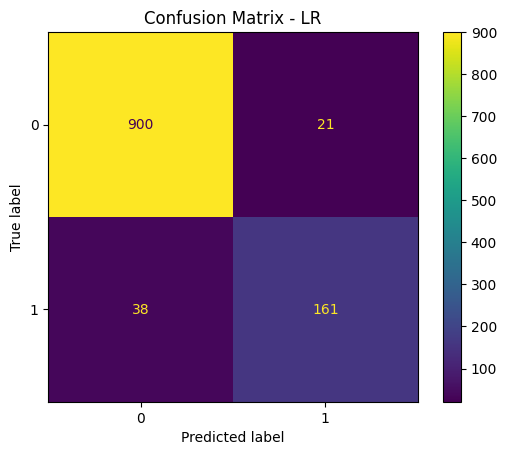

In [15]:
ConfusionMatrixDisplay.from_estimator(lr_model, X_test, y_test)
plt.title("Confusion Matrix - LR")
plt.show()

ROC Curve

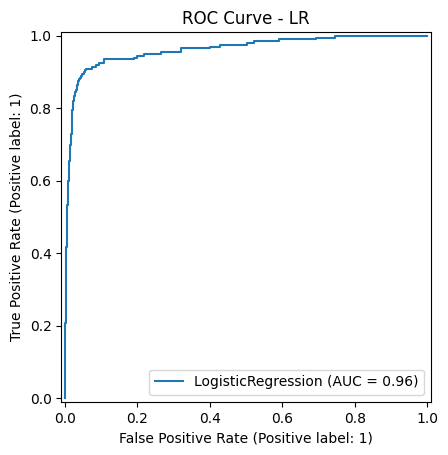

In [16]:
RocCurveDisplay.from_estimator(lr_model, X_test, y_test)
plt.title("ROC Curve - LR")
plt.show()

Precision-Recall Curve

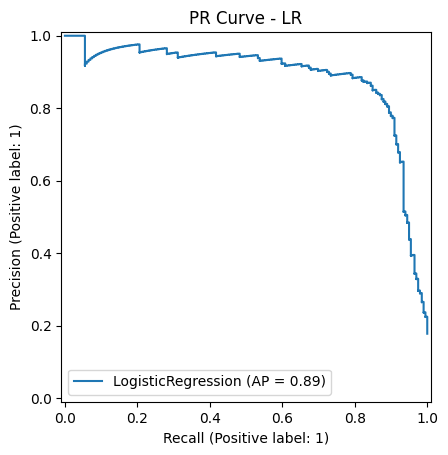

In [17]:
PrecisionRecallDisplay.from_estimator(lr_model, X_test, y_test)
plt.title("PR Curve - LR")
plt.show()